In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
PROJECT_DIR = Path(
    r"F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "figures"

DATA_PATH = PROCESSED_DIR / "daily_booking_demand.csv"

# Create output folders if they do not exist
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project path:", PROJECT_DIR)
print("Input file:", DATA_PATH)
print("Output folder:", OUTPUT_DIR)

Project path: F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand
Input file: F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand\data\processed\daily_booking_demand.csv
Output folder: F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand\outputs\figures


In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"File not found: {DATA_PATH}\n"
        "Run the previous notebook to create daily_booking_demand.csv."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (335, 2)


,DATE,BOOKING_COUNT
0,2026-01-08,13691.0
1,2026-01-09,NaN
2,2026-01-10,NaN
3,2026-01-11,NaN
4,2026-01-12,NaN


In [4]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"File not found: {DATA_PATH}\n"
        "Run the previous notebook to create daily_booking_demand.csv."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (335, 2)


,DATE,BOOKING_COUNT
0,2026-01-08,13691.0
1,2026-01-09,NaN
2,2026-01-10,NaN
3,2026-01-11,NaN
4,2026-01-12,NaN


In [5]:
print("Columns in dataset:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

Columns in dataset:
['DATE', 'BOOKING_COUNT']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 335 entries, 0 to 334
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   DATE           335 non-null    object 
 1   BOOKING_COUNT  12 non-null     float64
dtypes: float64(1), object(1)
memory usage: 5.4+ KB

Missing values:


DATE               0
BOOKING_COUNT    323
dtype: int64

In [7]:
# Check available columns
print("Dataset columns:", df.columns.tolist())

# Automatically identify date column
date_col = next(
    (col for col in df.columns
     if "date" in col.lower()),
    None
)

# Automatically identify booking demand column
demand_keywords = [
    "booking", "demand", "count",
    "volume", "quantity", "shipment"
]

demand_col = next(
    (col for col in df.columns
     if any(word in col.lower() for word in demand_keywords)
     and col != date_col),
    None
)

print("Date column:", date_col)
print("Demand column:", demand_col)

if date_col is None:
    raise ValueError("Date column not found.")

if demand_col is None:
    raise ValueError(
        "Booking demand column not found. "
        "Please check the dataset columns printed above."
    )

Dataset columns: ['DATE', 'BOOKING_COUNT']
Date column: DATE
Demand column: BOOKING_COUNT


In [12]:
print("Column names:")
print(df.columns.tolist())

Column names:
['DATE', 'BOOKING_COUNT']


In [13]:
display(df.head(10))

,DATE,BOOKING_COUNT
0,2026-01-08,13691.0
1,2026-01-09,NaN
2,2026-01-10,NaN
3,2026-01-11,NaN
4,2026-01-12,NaN
5,2026-01-13,NaN
6,2026-01-14,NaN
7,2026-01-15,NaN
8,2026-01-16,NaN
9,2026-01-17,NaN


In [15]:
# Clean column names
df.columns = df.columns.astype(str).str.strip()

# Display columns
print(df.columns.tolist())

# Find possible date columns
date_candidates = [
    col for col in df.columns
    if "date" in col.lower()
]

print("Possible date columns:", date_candidates)

['DATE', 'BOOKING_COUNT']
Possible date columns: ['DATE']


In [16]:
# Identify the date column
date_candidates = [
    "BKDATE", "date", "Date", "DATE",
    "booking_date", "ds"
]

date_col = next(
    (col for col in date_candidates if col in df.columns),
    None
)

# Identify the booking demand column
demand_candidates = [
    "booking_count", "Booking_Count",
    "daily_booking_demand", "demand",
    "Demand", "bookings", "y"
]

demand_col = next(
    (col for col in demand_candidates if col in df.columns),
    None
)

if date_col is None:
    raise ValueError(
        "Date column not found. Check the column names in Cell 4."
    )

if demand_col is None:
    raise ValueError(
        "Booking demand column not found. Check the column names in Cell 4."
    )

print("Date column:", date_col)
print("Demand column:", demand_col)

ValueError: Booking demand column not found. Check the column names in Cell 4.

In [18]:
print("Columns:")
for i, col in enumerate(df.columns):
    print(i, repr(col))

print("\nDataset preview:")
display(df.head())

Columns:
0 'DATE'
1 'BOOKING_COUNT'

Dataset preview:


,DATE,BOOKING_COUNT
0,2026-01-08,13691.0
1,2026-01-09,NaN
2,2026-01-10,NaN
3,2026-01-11,NaN
4,2026-01-12,NaN


In [22]:
  date_col = "BK_DATE"
demand_col = "TOTAL_BOOKINGS"

In [24]:
# Display the actual column names
print(df.columns.tolist())

['DATE', 'BOOKING_COUNT']


In [25]:
# Identify actual columns
date_col = "DATE"
demand_col = "BOOKING_COUNT"

print("Date column:", date_col)
print("Demand column:", demand_col)

Date column: DATE
Demand column: BOOKING_COUNT


In [26]:
# Convert date column
df[date_col] = pd.to_datetime(
    df[date_col],
    errors="coerce"
)

# Convert booking count to numeric
df[demand_col] = pd.to_numeric(
    df[demand_col],
    errors="coerce"
)

# Remove missing values
df = df.dropna(
    subset=[date_col, demand_col]
).copy()

print("Data cleaning completed!")
print("Dataset shape:", df.shape)
display(df.head())

Data cleaning completed!
Dataset shape: (12, 2)


,DATE,BOOKING_COUNT
0,2026-01-08,13691.0
31,2026-02-08,1913.0
59,2026-03-08,11381.0
90,2026-04-08,12809.0
120,2026-05-08,12559.0


In [27]:
df = df.sort_values(by=date_col).reset_index(drop=True)

print("Data sorted by date successfully!")
display(df.head())

Data sorted by date successfully!


,DATE,BOOKING_COUNT
0,2026-01-08,13691.0
1,2026-02-08,1913.0
2,2026-03-08,11381.0
3,2026-04-08,12809.0
4,2026-05-08,12559.0


In [29]:
# Display the actual column names
print(df.columns.tolist())

['DATE', 'BOOKING_COUNT']


In [30]:
display(df.head(5))

,DATE,BOOKING_COUNT
0,2026-01-08,13691.0
1,2026-02-08,1913.0
2,2026-03-08,11381.0
3,2026-04-08,12809.0
4,2026-05-08,12559.0


In [31]:
# Remove extra spaces from column names
df.columns = df.columns.astype(str).str.strip()

# Display column names and data types
print(df.dtypes)

DATE             datetime64[ns]
BOOKING_COUNT           float64
dtype: object


In [32]:
date_col = "ACTUAL_DATE_COLUMN"
demand_col = "ACTUAL_DEMAND_COLUMN"

print("Date:", date_col)
print("Demand:", demand_col)

Date: ACTUAL_DATE_COLUMN
Demand: ACTUAL_DEMAND_COLUMN


In [34]:

# Clean column names
df.columns = df.columns.astype(str).str.strip().str.upper()

# Identify the date column
date_candidates = [
    "BKDATE", "DATE", "BOOKING_DATE", "DS"
]

date_col = next(
    (col for col in date_candidates if col in df.columns),
    None
)

# Identify the booking demand column
demand_candidates = [
    "BOOKING_COUNT",
    "DAILY_BOOKING_DEMAND",
    "DEMAND",
    "BOOKINGS",
    "Y"
]

demand_col = next(
    (col for col in demand_candidates if col in df.columns),
    None
)

# Validate columns
if date_col is None:
    raise ValueError(
        f"Date column not found. Available columns: {df.columns.tolist()}"
    )

if demand_col is None:
    raise ValueError(
        f"Demand column not found. Available columns: {df.columns.tolist()}"
    )

# Display selected columns
print("Date column:", date_col)
print("Demand column:", demand_col)

# Convert columns to correct data types
df[date_col] = pd.to_datetime(
    df[date_col], errors="coerce"
)

df[demand_col] = pd.to_numeric(
    df[demand_col], errors="coerce"
)

# Remove invalid rows
df = df.dropna(
    subset=[date_col, demand_col]
).copy()

# Sort by date
df = df.sort_values(date_col).reset_index(drop=True)

print("\nData prepared successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Date column: DATE
Demand column: BOOKING_COUNT

Data prepared successfully!
Dataset shape: (12, 2)


,DATE,BOOKING_COUNT
0,2026-01-08,13691.0
1,2026-02-08,1913.0
2,2026-03-08,11381.0
3,2026-04-08,12809.0
4,2026-05-08,12559.0


In [35]:
df[date_col] = pd.to_datetime(
    df[date_col],
    errors="coerce"
)

df[demand_col] = pd.to_numeric(
    df[demand_col],
    errors="coerce"
)

# Remove rows with invalid dates or missing demand
df = df.dropna(subset=[date_col, demand_col]).copy()

# Sort data chronologically
df = df.sort_values(date_col).reset_index(drop=True)

print("Date and demand columns converted successfully!")
display(df.head())

Date and demand columns converted successfully!


,DATE,BOOKING_COUNT
0,2026-01-08,13691.0
1,2026-02-08,1913.0
2,2026-03-08,11381.0
3,2026-04-08,12809.0
4,2026-05-08,12559.0


In [36]:
duplicate_dates = df[date_col].duplicated().sum()

print("Duplicate dates:", duplicate_dates)

if duplicate_dates > 0:
    df = (
        df.groupby(date_col, as_index=False)[demand_col]
        .sum()
        .sort_values(date_col)
        .reset_index(drop=True)
    )

    print("Duplicate dates combined.")
else:
    print("No duplicate dates found.")

print("Updated dataset shape:", df.shape)

Duplicate dates: 0
No duplicate dates found.
Updated dataset shape: (12, 2)


In [37]:
date_range = pd.date_range(
    start=df[date_col].min(),
    end=df[date_col].max(),
    freq="D"
)

df = (
    df.set_index(date_col)
    .reindex(date_range)
    .rename_axis(date_col)
    .reset_index()
)

print("Missing demand values after reindexing:",
      df[demand_col].isna().sum())

display(df.head())

Missing demand values after reindexing: 323


,DATE,BOOKING_COUNT
0,2026-01-08,13691.0
1,2026-01-09,NaN
2,2026-01-10,NaN
3,2026-01-11,NaN
4,2026-01-12,NaN


In [38]:
# Use only if missing dates truly mean zero bookings
df[demand_col] = df[demand_col].fillna(0)

print("Missing dates filled with zero bookings.")

Missing dates filled with zero bookings.


In [39]:
df["year"] = df[date_col].dt.year
df["month"] = df[date_col].dt.month
df["day"] = df[date_col].dt.day

df["day_of_week"] = df[date_col].dt.dayofweek
df["day_name"] = df[date_col].dt.day_name()

df["week_of_year"] = (
    df[date_col].dt.isocalendar().week.astype(int)
)

df["quarter"] = df[date_col].dt.quarter

df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

df["is_month_start"] = (
    df[date_col].dt.is_month_start
).astype(int)

df["is_month_end"] = (
    df[date_col].dt.is_month_end
).astype(int)

print("Calendar features created successfully!")

display(df.head())

Calendar features created successfully!


,DATE,BOOKING_COUNT,year,month,day,day_of_week,day_name,week_of_year,quarter,is_weekend,is_month_start,is_month_end
0,2026-01-08,13691.0,2026,1,8,3,Thursday,2,1,0,0,0
1,2026-01-09,0.0,2026,1,9,4,Friday,2,1,0,0,0
2,2026-01-10,0.0,2026,1,10,5,Saturday,2,1,1,0,0
3,2026-01-11,0.0,2026,1,11,6,Sunday,2,1,1,0,0
4,2026-01-12,0.0,2026,1,12,0,Monday,3,1,0,0,0


In [40]:
df["lag_1"] = df[demand_col].shift(1)
df["lag_2"] = df[demand_col].shift(2)
df["lag_3"] = df[demand_col].shift(3)
df["lag_7"] = df[demand_col].shift(7)
df["lag_14"] = df[demand_col].shift(14)
df["lag_28"] = df[demand_col].shift(28)

print("Lag features created successfully!")

display(
    df[
        [date_col, demand_col,
         "lag_1", "lag_2", "lag_7", "lag_14", "lag_28"]
    ].head(15)
)

Lag features created successfully!


,DATE,BOOKING_COUNT,lag_1,lag_2,lag_7,lag_14,lag_28
0,2026-01-08,13691.0,NaN,NaN,NaN,NaN,NaN
1,2026-01-09,0.0,13691.0,NaN,NaN,NaN,NaN
2,2026-01-10,0.0,0.0,13691.0,NaN,NaN,NaN
3,2026-01-11,0.0,0.0,0.0,NaN,NaN,NaN
4,2026-01-12,0.0,0.0,0.0,NaN,NaN,NaN
5,2026-01-13,0.0,0.0,0.0,NaN,NaN,NaN
6,2026-01-14,0.0,0.0,0.0,NaN,NaN,NaN
7,2026-01-15,0.0,0.0,0.0,13691.0,NaN,NaN
8,2026-01-16,0.0,0.0,0.0,0.0,NaN,NaN
9,2026-01-17,0.0,0.0,0.0,0.0,NaN,NaN


In [41]:
df["rolling_mean_3"] = (
    df[demand_col]
    .shift(1)
    .rolling(window=3)
    .mean()
)

df["rolling_mean_7"] = (
    df[demand_col]
    .shift(1)
    .rolling(window=7)
    .mean()
)

df["rolling_mean_14"] = (
    df[demand_col]
    .shift(1)
    .rolling(window=14)
    .mean()
)

df["rolling_std_7"] = (
    df[demand_col]
    .shift(1)
    .rolling(window=7)
    .std()
)

print("Rolling features created successfully!")

display(
    df[
        [date_col, demand_col,
         "rolling_mean_3", "rolling_mean_7",
         "rolling_mean_14", "rolling_std_7"]
    ].head(20)
)

Rolling features created successfully!


,DATE,BOOKING_COUNT,rolling_mean_3,rolling_mean_7,rolling_mean_14,rolling_std_7
0,2026-01-08,13691.0,NaN,NaN,NaN,NaN
1,2026-01-09,0.0,NaN,NaN,NaN,NaN
2,2026-01-10,0.0,NaN,NaN,NaN,NaN
3,2026-01-11,0.0,4563.666667,NaN,NaN,NaN
4,2026-01-12,0.0,0.000000,NaN,NaN,NaN
5,2026-01-13,0.0,0.000000,NaN,NaN,NaN
6,2026-01-14,0.0,0.000000,NaN,NaN,NaN
7,2026-01-15,0.0,0.000000,1955.857143,NaN,5174.7116
8,2026-01-16,0.0,0.000000,0.000000,NaN,0.0000
9,2026-01-17,0.0,0.000000,0.000000,NaN,0.0000


In [42]:
df["demand_change_1"] = (
    df[demand_col].shift(1)
    - df[demand_col].shift(2)
)

df["demand_change_7"] = (
    df[demand_col].shift(1)
    - df[demand_col].shift(8)
)

print("Demand change features created successfully!")

display(
    df[
        [date_col, demand_col,
         "demand_change_1", "demand_change_7"]
    ].head(15)
)

Demand change features created successfully!


,DATE,BOOKING_COUNT,demand_change_1,demand_change_7
0,2026-01-08,13691.0,NaN,NaN
1,2026-01-09,0.0,NaN,NaN
2,2026-01-10,0.0,-13691.0,NaN
3,2026-01-11,0.0,0.0,NaN
4,2026-01-12,0.0,0.0,NaN
5,2026-01-13,0.0,0.0,NaN
6,2026-01-14,0.0,0.0,NaN
7,2026-01-15,0.0,0.0,NaN
8,2026-01-16,0.0,0.0,-13691.0
9,2026-01-17,0.0,0.0,0.0


In [43]:
df["day_sin"] = np.sin(
    2 * np.pi * df["day_of_week"] / 7
)

df["day_cos"] = np.cos(
    2 * np.pi * df["day_of_week"] / 7
)

df["month_sin"] = np.sin(
    2 * np.pi * (df["month"] - 1) / 12
)

df["month_cos"] = np.cos(
    2 * np.pi * (df["month"] - 1) / 12
)

print("Cyclical features created successfully!")

display(
    df[
        [date_col, "day_of_week", "day_sin",
         "day_cos", "month", "month_sin", "month_cos"]
    ].head()
)

Cyclical features created successfully!


,DATE,day_of_week,day_sin,day_cos,month,month_sin,month_cos
0,2026-01-08,3,0.433884,-0.900969,1,0.0,1.0
1,2026-01-09,4,-0.433884,-0.900969,1,0.0,1.0
2,2026-01-10,5,-0.974928,-0.222521,1,0.0,1.0
3,2026-01-11,6,-0.781831,0.623490,1,0.0,1.0
4,2026-01-12,0,0.000000,1.000000,1,0.0,1.0


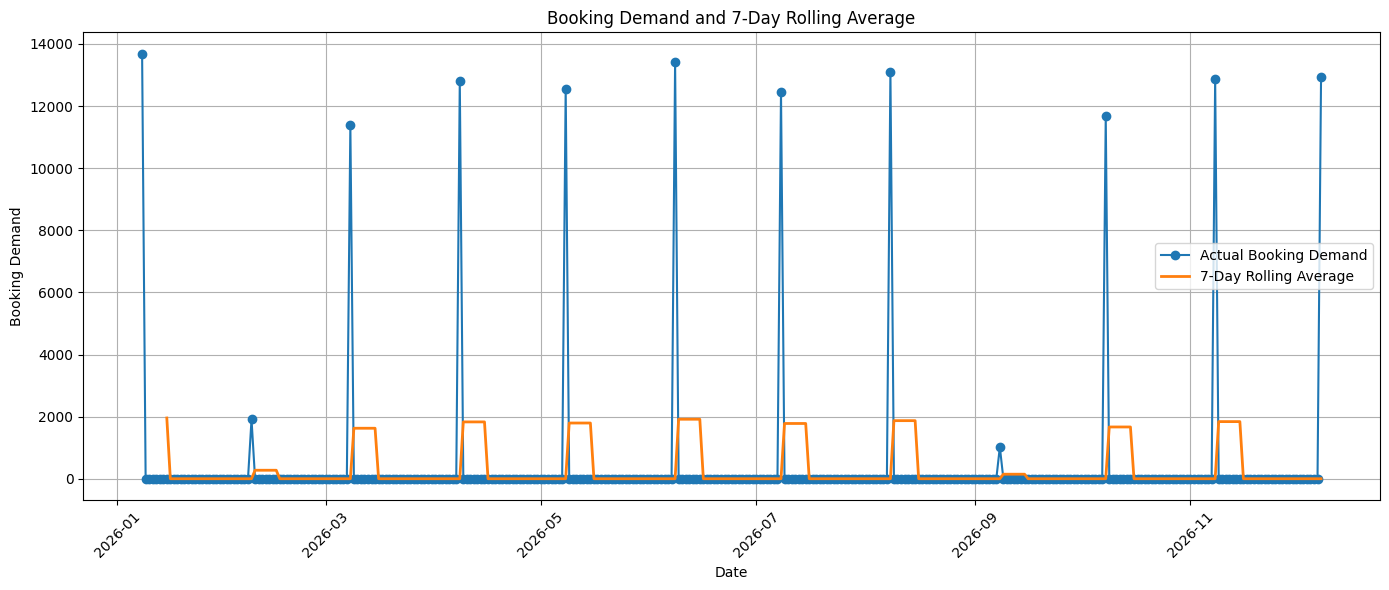

In [44]:
plt.figure(figsize=(14, 6))

plt.plot(
    df[date_col],
    df[demand_col],
    label="Actual Booking Demand",
    marker="o"
)

plt.plot(
    df[date_col],
    df["rolling_mean_7"],
    label="7-Day Rolling Average",
    linewidth=2
)

plt.title("Booking Demand and 7-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Booking Demand")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "booking_demand_rolling_average.png",
    dpi=300
)

plt.show()

In [45]:
print("Dataset shape:", df.shape)

print("\nAll columns:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isnull().sum())

print("\nFirst 10 rows:")
display(df.head(10))

Dataset shape: (335, 28)

All columns:
['DATE', 'BOOKING_COUNT', 'year', 'month', 'day', 'day_of_week', 'day_name', 'week_of_year', 'quarter', 'is_weekend', 'is_month_start', 'is_month_end', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_3', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'demand_change_1', 'demand_change_7', 'day_sin', 'day_cos', 'month_sin', 'month_cos']

Missing values:


DATE                0
BOOKING_COUNT       0
year                0
month               0
day                 0
day_of_week         0
day_name            0
week_of_year        0
quarter             0
is_weekend          0
is_month_start      0
is_month_end        0
lag_1               1
lag_2               2
lag_3               3
lag_7               7
lag_14             14
lag_28             28
rolling_mean_3      3
rolling_mean_7      7
rolling_mean_14    14
rolling_std_7       7
demand_change_1     2
demand_change_7     8
day_sin             0
day_cos             0
month_sin           0
month_cos           0
dtype: int64


First 10 rows:


,DATE,BOOKING_COUNT,year,month,day,day_of_week,day_name,week_of_year,quarter,is_weekend,is_month_start,is_month_end,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,rolling_mean_3,rolling_mean_7,rolling_mean_14,rolling_std_7,demand_change_1,demand_change_7,day_sin,day_cos,month_sin,month_cos
0,2026-01-08,13691.0,2026,1,8,3,Thursday,2,1,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.433884,-0.900969,0.0,1.0
1,2026-01-09,0.0,2026,1,9,4,Friday,2,1,0,0,0,13691.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.433884,-0.900969,0.0,1.0
2,2026-01-10,0.0,2026,1,10,5,Saturday,2,1,1,0,0,0.0,13691.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-13691.0,NaN,-0.974928,-0.222521,0.0,1.0
3,2026-01-11,0.0,2026,1,11,6,Sunday,2,1,1,0,0,0.0,0.0,13691.0,NaN,NaN,NaN,4563.666667,NaN,NaN,NaN,0.0,NaN,-0.781831,0.623490,0.0,1.0
4,2026-01-12,0.0,2026,1,12,0,Monday,3,1,0,0,0,0.0,0.0,0.0,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,0.0,NaN,0.000000,1.000000,0.0,1.0
5,2026-01-13,0.0,2026,1,13,1,Tuesday,3,1,0,0,0,0.0,0.0,0.0,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,0.0,NaN,0.781831,0.623490,0.0,1.0
6,2026-01-14,0.0,2026,1,14,2,Wednesday,3,1,0,0,0,0.0,0.0,0.0,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,0.0,NaN,0.974928,-0.222521,0.0,1.0
7,2026-01-15,0.0,2026,1,15,3,Thursday,3,1,0,0,0,0.0,0.0,0.0,13691.0,NaN,NaN,0.000000,1955.857143,NaN,5174.7116,0.0,NaN,0.433884,-0.900969,0.0,1.0
8,2026-01-16,0.0,2026,1,16,4,Friday,3,1,0,0,0,0.0,0.0,0.0,0.0,NaN,NaN,0.000000,0.000000,NaN,0.0000,0.0,-13691.0,-0.433884,-0.900969,0.0,1.0
9,2026-01-17,0.0,2026,1,17,5,Saturday,3,1,1,0,0,0.0,0.0,0.0,0.0,NaN,NaN,0.000000,0.000000,NaN,0.0000,0.0,0.0,-0.974928,-0.222521,0.0,1.0


In [46]:
feature_columns = [
    "year",
    "month",
    "day",
    "day_of_week",
    "week_of_year",
    "quarter",
    "is_weekend",
    "is_month_start",
    "is_month_end",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_3",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_std_7",
    "demand_change_1",
    "demand_change_7",
    "day_sin",
    "day_cos",
    "month_sin",
    "month_cos"
]

target_column = demand_col

model_df = df.dropna(
    subset=feature_columns + [target_column]
).copy()

print("Original dataset rows:", len(df))
print("Rows available for modeling:", len(model_df))
print("Number of features:", len(feature_columns))

display(model_df.head())

Original dataset rows: 335
Rows available for modeling: 307
Number of features: 25


,DATE,BOOKING_COUNT,year,month,day,day_of_week,day_name,week_of_year,quarter,is_weekend,is_month_start,is_month_end,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,rolling_mean_3,rolling_mean_7,rolling_mean_14,rolling_std_7,demand_change_1,demand_change_7,day_sin,day_cos,month_sin,month_cos
28,2026-02-05,0.0,2026,2,5,3,Thursday,6,1,0,0,0,0.0,0.0,0.0,0.0,0.0,13691.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.433884,-0.900969,0.5,0.866025
29,2026-02-06,0.0,2026,2,6,4,Friday,6,1,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,-0.433884,-0.900969,0.5,0.866025
30,2026-02-07,0.0,2026,2,7,5,Saturday,6,1,1,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,-0.974928,-0.222521,0.5,0.866025
31,2026-02-08,1913.0,2026,2,8,6,Sunday,6,1,1,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,-0.781831,0.623490,0.5,0.866025
32,2026-02-09,0.0,2026,2,9,0,Monday,7,1,0,0,0,1913.0,0.0,0.0,0.0,0.0,0.0,637.666667,273.285714,136.642857,723.046037,1913.0,1913.0,0.000000,1.000000,0.5,0.866025


In [47]:
FEATURED_PATH = PROCESSED_DIR / "feature_engineered_demand.csv"

model_df.to_csv(
    FEATURED_PATH,
    index=False
)

print("Feature-engineered dataset saved successfully!")
print("Saved file:", FEATURED_PATH)

Feature-engineered dataset saved successfully!
Saved file: F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand\data\processed\feature_engineered_demand.csv


In [48]:
X = model_df[feature_columns].copy()
y = model_df[target_column].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

X shape: (307, 25)
y shape: (307,)

Input features:
['year', 'month', 'day', 'day_of_week', 'week_of_year', 'quarter', 'is_weekend', 'is_month_start', 'is_month_end', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_3', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'demand_change_1', 'demand_change_7', 'day_sin', 'day_cos', 'month_sin', 'month_cos']

Target:
BOOKING_COUNT


In [49]:
split_index = int(len(model_df) * 0.8)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

train_dates = model_df[date_col].iloc[:split_index]
test_dates = model_df[date_col].iloc[split_index:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining period:")
print(train_dates.min(), "to", train_dates.max())

print("\nTesting period:")
print(test_dates.min(), "to", test_dates.max())

Training data: (245, 25)
Testing data: (62, 25)

Training period:
2026-02-05 00:00:00 to 2026-10-07 00:00:00

Testing period:
2026-10-08 00:00:00 to 2026-12-08 00:00:00


In [50]:
train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

train_path = PROCESSED_DIR / "train_features.csv"
test_path = PROCESSED_DIR / "test_features.csv"

train_df.to_csv(train_path, index=False)
test_df.to_csv(test_path, index=False)

print("Training features saved:", train_path)
print("Testing features saved:", test_path)

Training features saved: F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand\data\processed\train_features.csv
Testing features saved: F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand\data\processed\test_features.csv
